# Long time series and daily mean temperature

For each dataset: the full 30-min temperature series (15 Sep to 12 Oct 2026) and the daily mean temperature.

- profile mast: Vaisala HMP110 at 8, 4, 2, 1 and 0.5 m (`profile.csv`)
- iWS station: T sensor, RH/T sensor and CNR4 radiometer body (`iws.csv`)
- CNR1 radiometer body (`cnr1.csv`)
- turbulence mast: sonic temperature and thermocouples Tc1 and Tc2 (`turb.csv`)

All times are in CEST (iWS is logged in UTC). The loggers stamp each 30-min average at the end of its interval, so 30 min is subtracted to put every value on the day it was measured.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ds_profile = pd.read_csv("../data/profile.csv")
ds_iWS = pd.read_csv("../data/iws.csv")
ds_CNR1 = pd.read_csv("../data/cnr1.csv")
ds_turb = pd.read_csv("../data/turb.csv")

In [3]:
#creating timestamps in CEST at the start of each 30-min interval
ds_profile["datetime"] = pd.to_datetime("2026-01-01")+pd.to_timedelta(ds_profile["DOY"]-1,unit="D").dt.round("min")-pd.Timedelta("30min")
ds_CNR1["datetime"] = pd.to_datetime("2026-01-01")+pd.to_timedelta(ds_CNR1["doy"]-1,unit="D").dt.round("min")-pd.Timedelta("30min")
ds_turb["datetime"] = pd.to_datetime("2026-01-01")+pd.to_timedelta(ds_turb["DOY"]-1,unit="D").dt.round("min")-pd.Timedelta("30min")

ds_iWS["datetime"] = (pd.to_datetime(ds_iWS[["year", "mm", "dd"]].rename(columns={"mm": "month", "dd": "day"}))
    + pd.to_timedelta(ds_iWS["hh"], unit="h")
    + pd.to_timedelta(ds_iWS["minutes"], unit="m")
    + pd.to_timedelta(2, unit="h")                     #iWS logs in UTC, the other loggers in CEST (UTC+2)
    - pd.Timedelta("30min"))

ds_profile = ds_profile.set_index("datetime")
ds_iWS = ds_iWS.set_index("datetime")
ds_CNR1 = ds_CNR1.set_index("datetime")
ds_turb = ds_turb.set_index("datetime")

In [4]:
#removing bad values (see README, Problems found in the data)
ds_profile = ds_profile.loc[ds_profile["T1"] > -10]                    #first profile record is invalid (about -25 C)
ds_CNR1 = ds_CNR1.loc[ds_CNR1["SWTop_Avg"].between(-20, 1400)]         #first record and the logger repair on 28 Sep
ds_iWS = ds_iWS.replace(327.67, float("nan"))                          #327.67 is the iWS fill value
ds_turb.loc[(ds_turb["Tc1"] - ds_turb["Ts"]).abs() > 3, "Tc1"] = float("nan")   #thermocouple spikes

In [5]:
temp_vaisala_8m = ds_profile["T1"]
temp_vaisala_4m = ds_profile["T2"]
temp_vaisala_2m = ds_profile["T3"]
temp_vaisala_1m = ds_profile["T4"]
temp_vaisala_05m = ds_profile["T5"]

temp_iws_t = ds_iWS["THUTavg"]         #iWS temperature sensor
temp_iws_rht = ds_iWS["RHTavg"]        #temperature of the iWS humidity sensor
temp_cnr4 = ds_iWS["NRTavg"]           #CNR4 radiometer body

temp_cnr1 = ds_CNR1["cnr1_T_C_Avg"]    #CNR1 radiometer body

temp_sonic = ds_turb["Ts"]             #temperature deduced from sonic anemometer data
temp_tc1 = ds_turb["Tc1"]              #thermocouple close to the sonic anemometer
temp_tc2 = ds_turb["Tc2"]              #thermocouple close to the vertical propeller

## Daily mean

A day has 48 half-hour values. A daily mean is only kept when at least 44 of them are there, so incomplete days (the first and last day, gaps, Tc1 after 28 Sep) are left out.

In [6]:
daily_vaisala_8m = temp_vaisala_8m.resample("D").mean()[temp_vaisala_8m.resample("D").count() >= 44]
daily_vaisala_4m = temp_vaisala_4m.resample("D").mean()[temp_vaisala_4m.resample("D").count() >= 44]
daily_vaisala_2m = temp_vaisala_2m.resample("D").mean()[temp_vaisala_2m.resample("D").count() >= 44]
daily_vaisala_1m = temp_vaisala_1m.resample("D").mean()[temp_vaisala_1m.resample("D").count() >= 44]
daily_vaisala_05m = temp_vaisala_05m.resample("D").mean()[temp_vaisala_05m.resample("D").count() >= 44]

daily_iws_t = temp_iws_t.resample("D").mean()[temp_iws_t.resample("D").count() >= 44]
daily_iws_rht = temp_iws_rht.resample("D").mean()[temp_iws_rht.resample("D").count() >= 44]
daily_cnr4 = temp_cnr4.resample("D").mean()[temp_cnr4.resample("D").count() >= 44]

daily_cnr1 = temp_cnr1.resample("D").mean()[temp_cnr1.resample("D").count() >= 44]

daily_sonic = temp_sonic.resample("D").mean()[temp_sonic.resample("D").count() >= 44]
daily_tc1 = temp_tc1.resample("D").mean()[temp_tc1.resample("D").count() >= 44]
daily_tc2 = temp_tc2.resample("D").mean()[temp_tc2.resample("D").count() >= 44]

print("valid days: Vaisala", len(daily_vaisala_4m), "| iWS", len(daily_iws_t), "| CNR1", len(daily_cnr1),
      "| CNR4", len(daily_cnr4), "| sonic", len(daily_sonic), "| Tc1", len(daily_tc1), "| Tc2", len(daily_tc2))

valid days: Vaisala 26 | iWS 25 | CNR1 26 | CNR4 25 | sonic 25 | Tc1 11 | Tc2 26


## Long time series and daily mean per dataset

Thin line: 30-min values. Dots: daily mean, plotted at noon of each day.

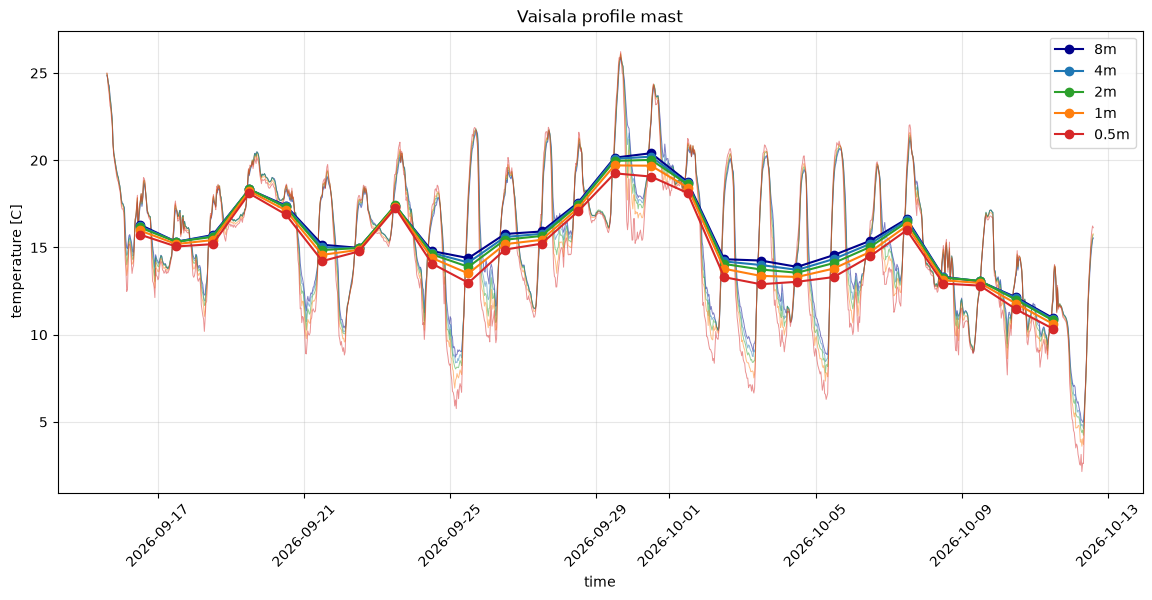

In [7]:
plt.figure(figsize=[14,6])
plt.plot(temp_vaisala_8m.index,temp_vaisala_8m,c="darkblue",lw=0.7,alpha=0.5)
plt.plot(temp_vaisala_4m.index,temp_vaisala_4m,c="tab:blue",lw=0.7,alpha=0.5)
plt.plot(temp_vaisala_2m.index,temp_vaisala_2m,c="tab:green",lw=0.7,alpha=0.5)
plt.plot(temp_vaisala_1m.index,temp_vaisala_1m,c="tab:orange",lw=0.7,alpha=0.5)
plt.plot(temp_vaisala_05m.index,temp_vaisala_05m,c="tab:red",lw=0.7,alpha=0.5)
plt.plot(daily_vaisala_8m.index+pd.Timedelta("12h"),daily_vaisala_8m,c="darkblue",marker="o",label="8m")
plt.plot(daily_vaisala_4m.index+pd.Timedelta("12h"),daily_vaisala_4m,c="tab:blue",marker="o",label="4m")
plt.plot(daily_vaisala_2m.index+pd.Timedelta("12h"),daily_vaisala_2m,c="tab:green",marker="o",label="2m")
plt.plot(daily_vaisala_1m.index+pd.Timedelta("12h"),daily_vaisala_1m,c="tab:orange",marker="o",label="1m")
plt.plot(daily_vaisala_05m.index+pd.Timedelta("12h"),daily_vaisala_05m,c="tab:red",marker="o",label="0.5m")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.xlabel("time")
plt.ylabel("temperature [C]")
plt.title("Vaisala profile mast")
plt.show()

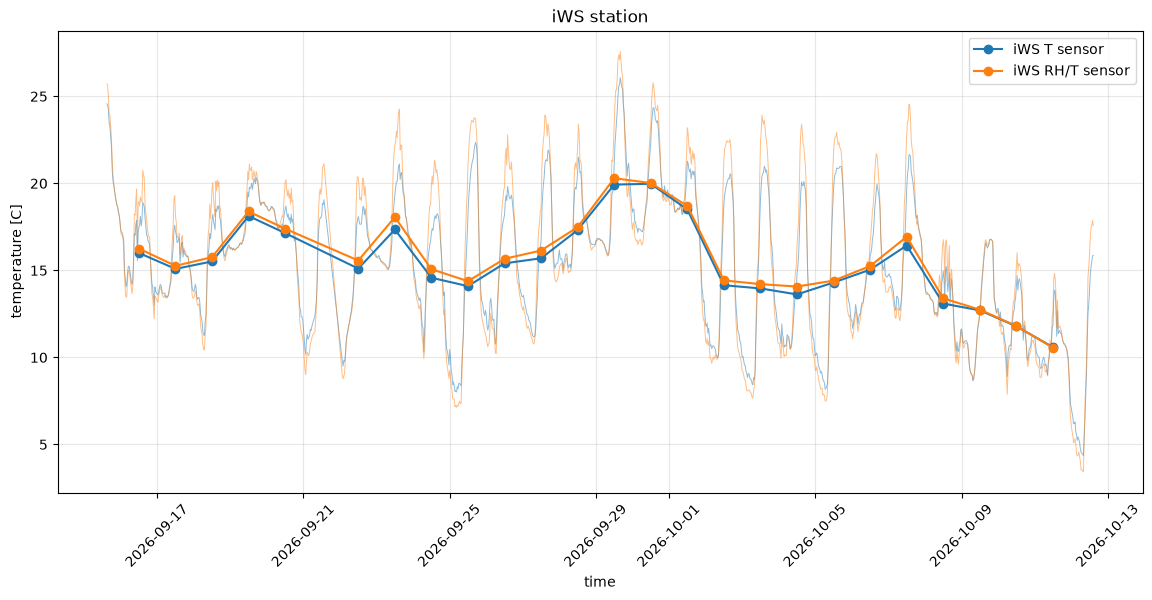

In [8]:
plt.figure(figsize=[14,6])
plt.plot(temp_iws_t.index,temp_iws_t,c="tab:blue",lw=0.7,alpha=0.5)
plt.plot(temp_iws_rht.index,temp_iws_rht,c="tab:orange",lw=0.7,alpha=0.5)
plt.plot(daily_iws_t.index+pd.Timedelta("12h"),daily_iws_t,c="tab:blue",marker="o",label="iWS T sensor")
plt.plot(daily_iws_rht.index+pd.Timedelta("12h"),daily_iws_rht,c="tab:orange",marker="o",label="iWS RH/T sensor")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.xlabel("time")
plt.ylabel("temperature [C]")
plt.title("iWS station")
plt.show()

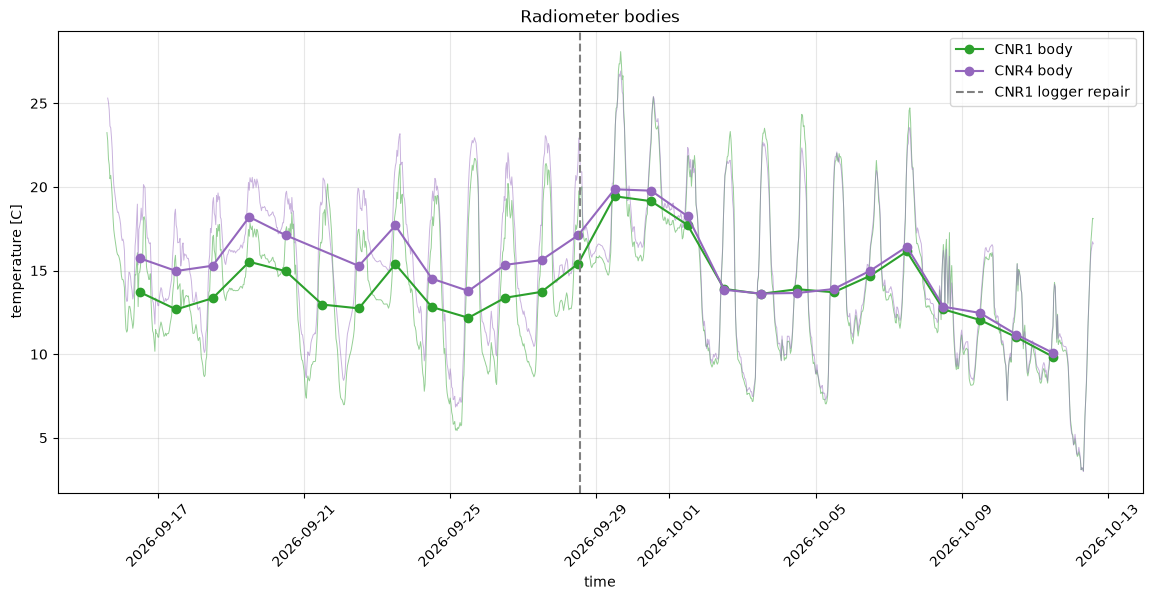

In [9]:
plt.figure(figsize=[14,6])
plt.plot(temp_cnr1.index,temp_cnr1,c="tab:green",lw=0.7,alpha=0.5)
plt.plot(temp_cnr4.index,temp_cnr4,c="tab:purple",lw=0.7,alpha=0.5)
plt.plot(daily_cnr1.index+pd.Timedelta("12h"),daily_cnr1,c="tab:green",marker="o",label="CNR1 body")
plt.plot(daily_cnr4.index+pd.Timedelta("12h"),daily_cnr4,c="tab:purple",marker="o",label="CNR4 body")
plt.axvline(pd.Timestamp("2026-09-28 13:15"),c="gray",ls="--",label="CNR1 logger repair")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.xlabel("time")
plt.ylabel("temperature [C]")
plt.title("Radiometer bodies")
plt.show()

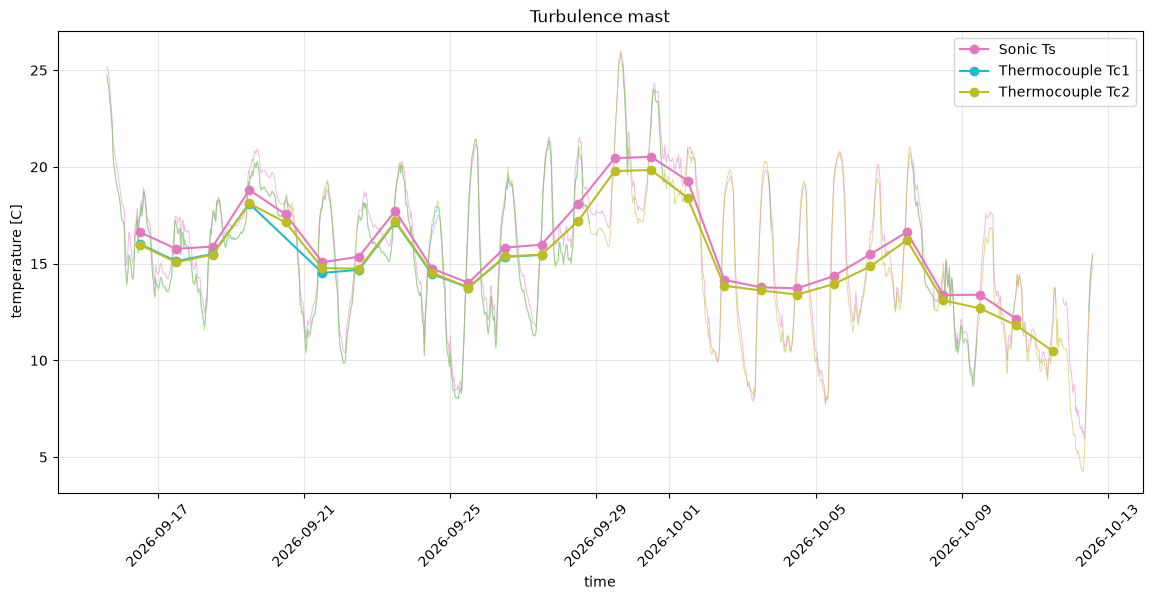

In [10]:
plt.figure(figsize=[14,6])
plt.plot(temp_sonic.index,temp_sonic,c="tab:pink",lw=0.7,alpha=0.5)
plt.plot(temp_tc1.index,temp_tc1,c="tab:cyan",lw=0.7,alpha=0.5)
plt.plot(temp_tc2.index,temp_tc2,c="tab:olive",lw=0.7,alpha=0.5)
plt.plot(daily_sonic.index+pd.Timedelta("12h"),daily_sonic,c="tab:pink",marker="o",label="Sonic Ts")
plt.plot(daily_tc1.index+pd.Timedelta("12h"),daily_tc1,c="tab:cyan",marker="o",label="Thermocouple Tc1")
plt.plot(daily_tc2.index+pd.Timedelta("12h"),daily_tc2,c="tab:olive",marker="o",label="Thermocouple Tc2")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.xlabel("time")
plt.ylabel("temperature [C]")
plt.title("Turbulence mast")
plt.show()

## Daily mean of all sensors at about 4 m

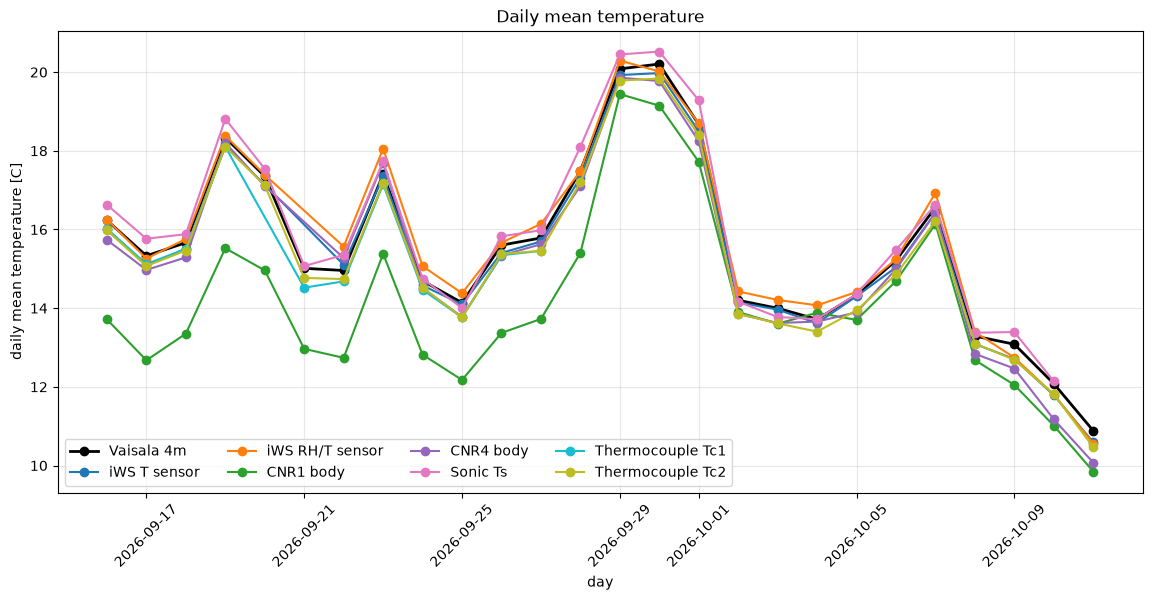

In [11]:
plt.figure(figsize=[14,6])
plt.plot(daily_vaisala_4m.index,daily_vaisala_4m,c="black",marker="o",lw=2,label="Vaisala 4m")
plt.plot(daily_iws_t.index,daily_iws_t,c="tab:blue",marker="o",label="iWS T sensor")
plt.plot(daily_iws_rht.index,daily_iws_rht,c="tab:orange",marker="o",label="iWS RH/T sensor")
plt.plot(daily_cnr1.index,daily_cnr1,c="tab:green",marker="o",label="CNR1 body")
plt.plot(daily_cnr4.index,daily_cnr4,c="tab:purple",marker="o",label="CNR4 body")
plt.plot(daily_sonic.index,daily_sonic,c="tab:pink",marker="o",label="Sonic Ts")
plt.plot(daily_tc1.index,daily_tc1,c="tab:cyan",marker="o",label="Thermocouple Tc1")
plt.plot(daily_tc2.index,daily_tc2,c="tab:olive",marker="o",label="Thermocouple Tc2")
plt.legend(ncol=4)
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.xlabel("day")
plt.ylabel("daily mean temperature [C]")
plt.title("Daily mean temperature")
plt.show()

## Daily mean difference from the Vaisala at 4 m

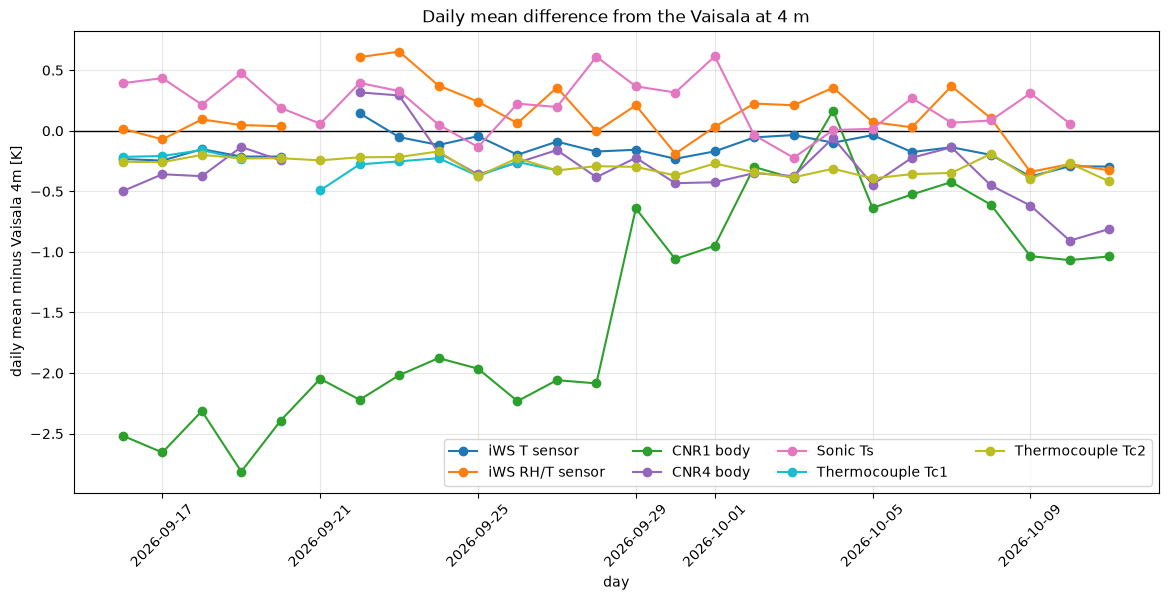

In [12]:
#difference of each sensor's daily mean from the Vaisala at 4 m
diff_iws_t = daily_iws_t - daily_vaisala_4m
diff_iws_rht = daily_iws_rht - daily_vaisala_4m
diff_cnr1 = daily_cnr1 - daily_vaisala_4m
diff_cnr4 = daily_cnr4 - daily_vaisala_4m
diff_sonic = daily_sonic - daily_vaisala_4m
diff_tc1 = daily_tc1 - daily_vaisala_4m
diff_tc2 = daily_tc2 - daily_vaisala_4m

plt.figure(figsize=[14,6])
plt.axhline(0,c="black",lw=1)
plt.plot(diff_iws_t.index,diff_iws_t,c="tab:blue",marker="o",label="iWS T sensor")
plt.plot(diff_iws_rht.index,diff_iws_rht,c="tab:orange",marker="o",label="iWS RH/T sensor")
plt.plot(diff_cnr1.index,diff_cnr1,c="tab:green",marker="o",label="CNR1 body")
plt.plot(diff_cnr4.index,diff_cnr4,c="tab:purple",marker="o",label="CNR4 body")
plt.plot(diff_sonic.index,diff_sonic,c="tab:pink",marker="o",label="Sonic Ts")
plt.plot(diff_tc1.index,diff_tc1,c="tab:cyan",marker="o",label="Thermocouple Tc1")
plt.plot(diff_tc2.index,diff_tc2,c="tab:olive",marker="o",label="Thermocouple Tc2")
plt.legend(ncol=4)
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.xlabel("day")
plt.ylabel("daily mean minus Vaisala 4m [K]")
plt.title("Daily mean difference from the Vaisala at 4 m")
plt.show()